# CD-T Parametric Circuit Analysis
This notebook allows you to instantly extract, visualize, and evaluate circuits of varying sizes seamlessly.

In [1]:
import torch
import json
import os
import random
from IPython.display import SVG, display, Markdown

# Add root dir to path if needed
import sys
sys.path.append('.')

from models.llava_wrapper import LlavaWrapper
from tasks.hallucination_vlm import HallucinationDataset
from find_circuit_from_matrix import find_circuit
from visualize_circuit import generate_svg
from methods.hallucination_circuit import prop_LLaVA
from pyfunctions.wrappers import Node


### 1. One-Time Setup: Load Model and Adjacency Matrix
Run this cell once. It loads the 14GB model into VRAM and caches the Mean Activations and 1024x1024 Adjacency Matrix.

In [2]:
model_id = "llava-hf/llava-1.5-7b-hf"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Loading LLaVA-1.5...")
wrapper = LlavaWrapper(model_id=model_id, device=device)

print("Loading Hallucination Database (POPE)...")
with open("data/hallucinations/hallucinations.json", "r") as f:
    eval_data = json.load(f)

print("Initializing Dataset Class...")
dataset = HallucinationDataset(eval_data, wrapper, None, mean_cache_path="data/mean_activations.pt")

print("Loading 1024x1024 Adjacency Matrix...")
matrix_path = "adjacency_matrix.pt"
adj = torch.load(matrix_path, map_location="cpu")

num_heads = wrapper.num_heads
num_layers = wrapper.num_layers
print(f"Ready! Network Dimensions: {num_layers} layers x {num_heads} heads")


Loading LLaVA-1.5...
Loading llava-hf/llava-1.5-7b-hf on cuda in fp16...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Loading Hallucination Database (POPE)...
Initializing Dataset Class...
Processing hallucination examples...


Processing examples: 100%|██████████| 50/50 [00:16<00:00,  3.03it/s]


Loading precomputed mean activations from data/mean_activations.pt...
Loaded mean activations successfully.
Loading 1024x1024 Adjacency Matrix...
Ready! Network Dimensions: 32 layers x 32 heads


### 2. Define the Pipeline Methods
This cell defines the automatic one-click Extract $\rightarrow$ Visualize $\rightarrow$ Evaluate pipeline.

In [8]:
def check_faithfulness(dataset, wrapper, circuit_list, num_evals=10):
    circuit_nodes = set()
    for item in circuit_list:
        circuit_nodes.add((item["layer"], item["head"], -1))
        
    full_model_scores = []
    circuit_only_scores = []
    
    examples = dataset.hallucination_examples[:num_evals] if num_evals else dataset.hallucination_examples
    for i, example in enumerate(examples):
        if i==33:
            continue
        
        ans_pos = example["answer_position"]
        vis_pos = example["visual_positions"]
        q_pos = example["question_positions"]
        
        hall_id = example.get("hallucinated_token_id")
        corr_id = example.get("correct_token_id")
        if hall_id is None or corr_id is None:
            hall_id = wrapper.get_correct_token_id("Yes")
            corr_id = wrapper.get_correct_token_id("No")
            
        raw_d_i = wrapper.W_U[hall_id] - wrapper.W_U[corr_id]
        d_i = raw_d_i / torch.norm(raw_d_i, p=2)
            
        mean_c = dataset.get_mean_correct(vis_pos, q_pos, ans_pos)
        
        prompt = wrapper.get_prompt(example["question"])
        inputs = wrapper.processor(text=prompt, images=example["image_loaded"], return_tensors="pt")
        if "pixel_values" in inputs:
            inputs["pixel_values"] = inputs["pixel_values"].to(torch.float16)
        inputs = {k: v.to(wrapper.device) if torch.is_tensor(v) else v for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = wrapper.model(**inputs, output_hidden_states=True, return_dict=True)
            base_embeds = outputs.hidden_states[0].to(torch.float16)
        
        # 1. Full Model Beta
        all_nodes = [Node(layer_idx=l, sequence_idx=-1, attn_head_idx=h) for l in range(wrapper.num_layers) for h in range(wrapper.num_heads)]
        rel_full, _ = prop_LLaVA(dataset, [all_nodes], base_embeds, mean_c)
        full_beta = torch.dot(d_i, rel_full[0, ans_pos, :]).item()
        
        # 2. Circuit Beta
        circuit_nodes_list = [Node(layer_idx=l, sequence_idx=-1, attn_head_idx=h) for (l, h, seq) in circuit_nodes]
        rel_C, _ = prop_LLaVA(dataset, [circuit_nodes_list], base_embeds, mean_c)
        C_beta = torch.dot(d_i, rel_C[0, ans_pos, :]).item()
        
        full_model_scores.append(full_beta)
        circuit_only_scores.append(C_beta)

    mean_full = sum(full_model_scores) / max(1, len(full_model_scores))
    mean_C = sum(circuit_only_scores) / max(1, len(circuit_only_scores))
    return mean_C / (mean_full if abs(mean_full) > 1e-6 else 1e-6)


def generate_random_circuit(num_nodes=8):
    random_circ = []
    seen = set()
    while len(random_circ) < num_nodes:
        l = random.randint(0, num_layers-1)
        h = random.randint(0, num_heads-1)
        if (l, h) not in seen:
            seen.add((l, h))
            random_circ.append({"layer": l, "head": h})
    return random_circ


def extract_and_evaluate_circuit(num_outliers=2, num_evals=10):
    display(Markdown(f"## Evaluating Circuit with `num_outliers={num_outliers}`"))
    
    # 1. Extract
    print("1. Running Iterative Backward Search...")
    circuit, iterations = find_circuit(
        adj, 
        num_layers=num_layers, 
        num_heads=num_heads,
        num_outliers=num_outliers
    )
    K = len(circuit)
    print(f"   -> Found circuit with exactly {K} nodes.")
    
    # 2. Visualize
    print("2. Generating SVG Visualization...")
    temp_json = "temp_nb_circuit.json"
    temp_svg = "temp_nb_viz.svg"
    with open(temp_json, "w") as f:
        json.dump({"circuit": circuit}, f, indent=4)
    generate_svg(temp_json, temp_svg)
    display(SVG(filename=temp_svg))
    
    # 3. Evaluate Discovered
    print(f"\n3. Evaluating Faithfulness of Discovered Circuit on {num_evals} examples...")
    discovered_faithfulness = check_faithfulness(dataset, wrapper, circuit, num_evals=num_evals)
    
    # 4. Evaluate Random Baseline
    print(f"4. Generating & Evaluating Random Control Circuit ({K} nodes)...")
    random_circuit = generate_random_circuit(K)
    random_faithfulness = check_faithfulness(dataset, wrapper, random_circuit, num_evals=num_evals)
    
    display(Markdown(f"### Results (`num_outliers={num_outliers}`, `Total Nodes={K}`)"))
    display(Markdown(f"- **Discovered Circuit Faithfulness:** `{discovered_faithfulness:.2%}`"))
    display(Markdown(f"- **Random Baseline Faithfulness:** `{random_faithfulness:.2%}`"))
    print("="*60)


### 3. Run Experiments
Call the pipeline function below with different values. Everything will natively output below the cell!

## Evaluating Circuit with `num_outliers=1`

1. Running Iterative Backward Search...
Iteration 0 (target=logits): ['L29H22']
Iteration 1 (target=['L29H22']): Selected ['L25H2']
Iteration 2 (target=['L25H2']): Selected ['L21H26']
Iteration 3 (target=['L21H26']): Selected ['L8H18']
Iteration 4 (target=['L8H18']): Selected ['L7H1']
Iteration 5 (target=['L7H1']): Selected ['L6H18']
Iteration 6 (target=['L6H18']): Selected ['L5H18']
Iteration 7 (target=['L5H18']): Selected ['L4H22']
Iteration 8 (target=['L4H22']): Selected ['L3H21']
Iteration 9 (target=['L3H21']): Selected ['L2H23']
Iteration 10 (target=['L2H23']): Selected ['L1H17']
Iteration 11 (target=['L1H17']): Selected ['L0H15']
All targets at layer 0. Stopping.
   -> Found circuit with exactly 12 nodes.
2. Generating SVG Visualization...
Reading circuit from temp_nb_circuit.json...
High-dimensional SVG visualization saved successfully to temp_nb_viz.svg!


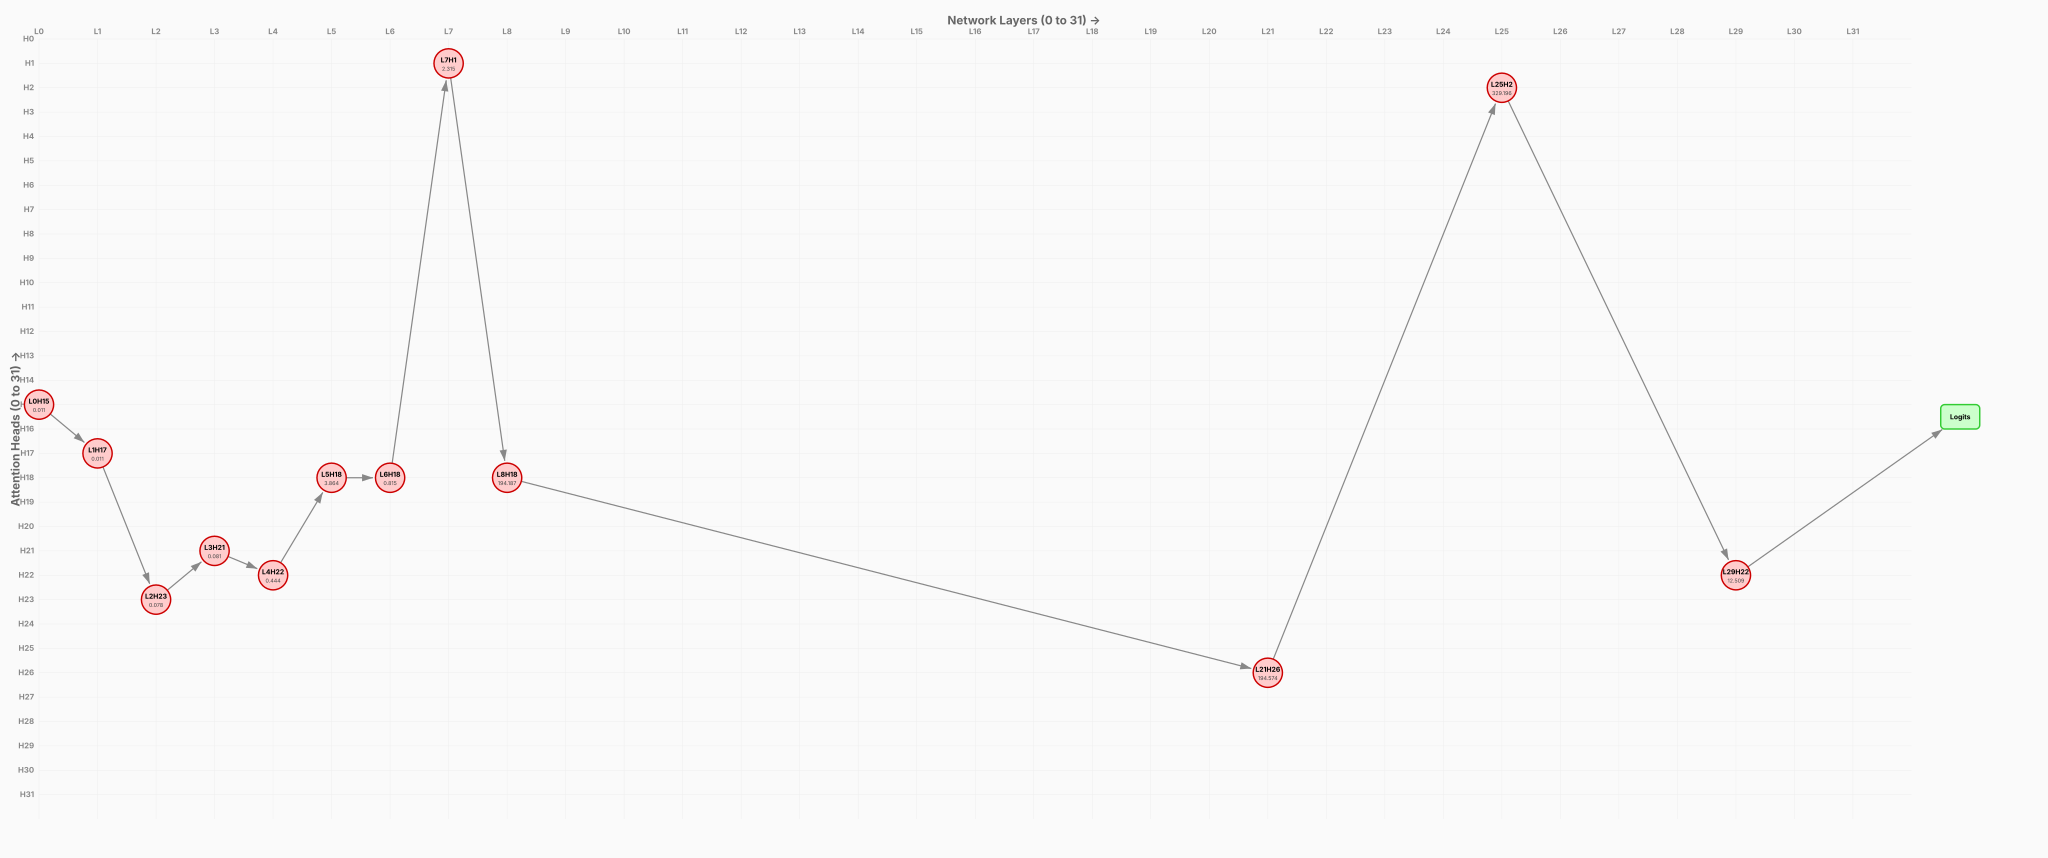


3. Evaluating Faithfulness of Discovered Circuit on 50 examples...
4. Generating & Evaluating Random Control Circuit (12 nodes)...


### Results (`num_outliers=1`, `Total Nodes=12`)

- **Discovered Circuit Faithfulness:** `34.52%`

- **Random Baseline Faithfulness:** `16.42%`

In [9]:
extract_and_evaluate_circuit(num_outliers=1, num_evals=50)


## Evaluating Circuit with `num_outliers=2`

1. Running Iterative Backward Search...
Iteration 0 (target=logits): ['L29H22', 'L7H25']
Iteration 1 (target=['L29H22', 'L7H25']): Selected ['L25H2', 'L21H6']
Iteration 2 (target=['L25H2', 'L21H6']): Selected ['L21H26', 'L17H18']
Iteration 3 (target=['L21H26', 'L17H18']): Selected ['L8H18', 'L20H2']
Iteration 4 (target=['L8H18', 'L20H2']): Selected ['L14H15', 'L13H17']
Iteration 5 (target=['L14H15', 'L13H17']): Selected ['L6H13', 'L5H23']
Iteration 6 (target=['L6H13', 'L5H23']): Selected ['L3H30', 'L1H19']
Iteration 7 (target=['L3H30', 'L1H19']): Selected ['L2H13', 'L2H30']
Iteration 8 (target=['L2H13', 'L2H30']): Selected ['L1H24', 'L1H16']
Iteration 9 (target=['L1H24', 'L1H16']): Selected ['L0H15', 'L0H25']
All targets at layer 0. Stopping.
   -> Found circuit with exactly 20 nodes.
2. Generating SVG Visualization...
Reading circuit from temp_nb_circuit.json...
High-dimensional SVG visualization saved successfully to temp_nb_viz.svg!


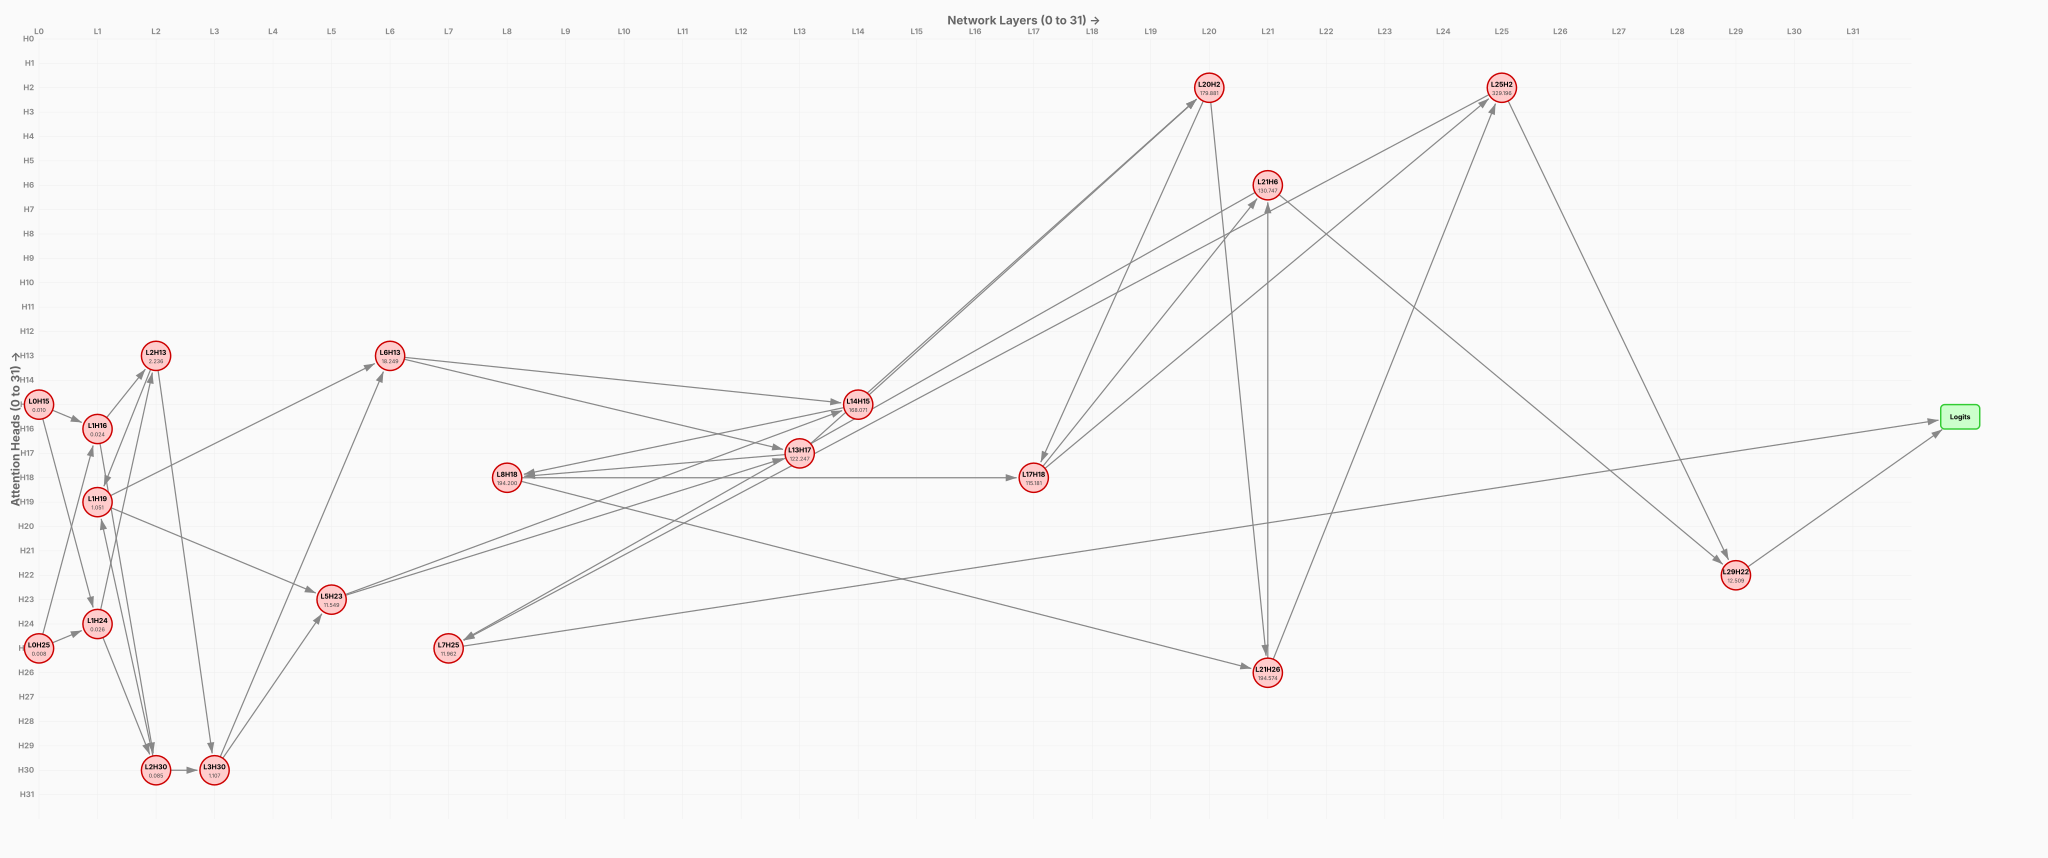


3. Evaluating Faithfulness of Discovered Circuit on 50 examples...
4. Generating & Evaluating Random Control Circuit (20 nodes)...


### Results (`num_outliers=2`, `Total Nodes=20`)

- **Discovered Circuit Faithfulness:** `44.51%`

- **Random Baseline Faithfulness:** `31.50%`

In [10]:
extract_and_evaluate_circuit(num_outliers=2, num_evals=50)


## Evaluating Circuit with `num_outliers=4`

1. Running Iterative Backward Search...
Iteration 0 (target=logits): ['L29H22', 'L7H25', 'L24H27', 'L6H6']
Iteration 1 (target=['L29H22', 'L7H25', 'L24H27', 'L6H6']): Selected ['L25H2', 'L21H6', 'L3H1', 'L18H31']
Iteration 2 (target=['L25H2', 'L21H6', 'L3H1', 'L18H31']): Selected ['L21H26', 'L17H18', 'L7H4', 'L16H16']
Iteration 3 (target=['L21H26', 'L17H18', 'L7H4', 'L16H16']): Selected ['L8H18', 'L20H2', 'L14H17', 'L13H9']
Iteration 4 (target=['L8H18', 'L20H2', 'L14H17', 'L13H9']): Selected ['L14H15', 'L13H17', 'L4H9', 'L8H8']
Iteration 5 (target=['L14H15', 'L13H17', 'L4H9', 'L8H8']): Selected ['L6H13', 'L4H18', 'L5H23', 'L7H5']
Iteration 6 (target=['L6H13', 'L4H18', 'L5H23', 'L7H5']): Selected ['L4H7', 'L6H18', 'L4H29', 'L3H11']
Iteration 7 (target=['L4H7', 'L6H18', 'L4H29', 'L3H11']): Selected ['L3H22', 'L5H18', 'L2H23', 'L3H15']
Iteration 8 (target=['L3H22', 'L5H18', 'L2H23', 'L3H15']): Selected ['L4H22', 'L2H15', 'L4H17', 'L3H2']
Iteration 9 (target=['L4H22', 'L2H15', 'L4H17', 'L3

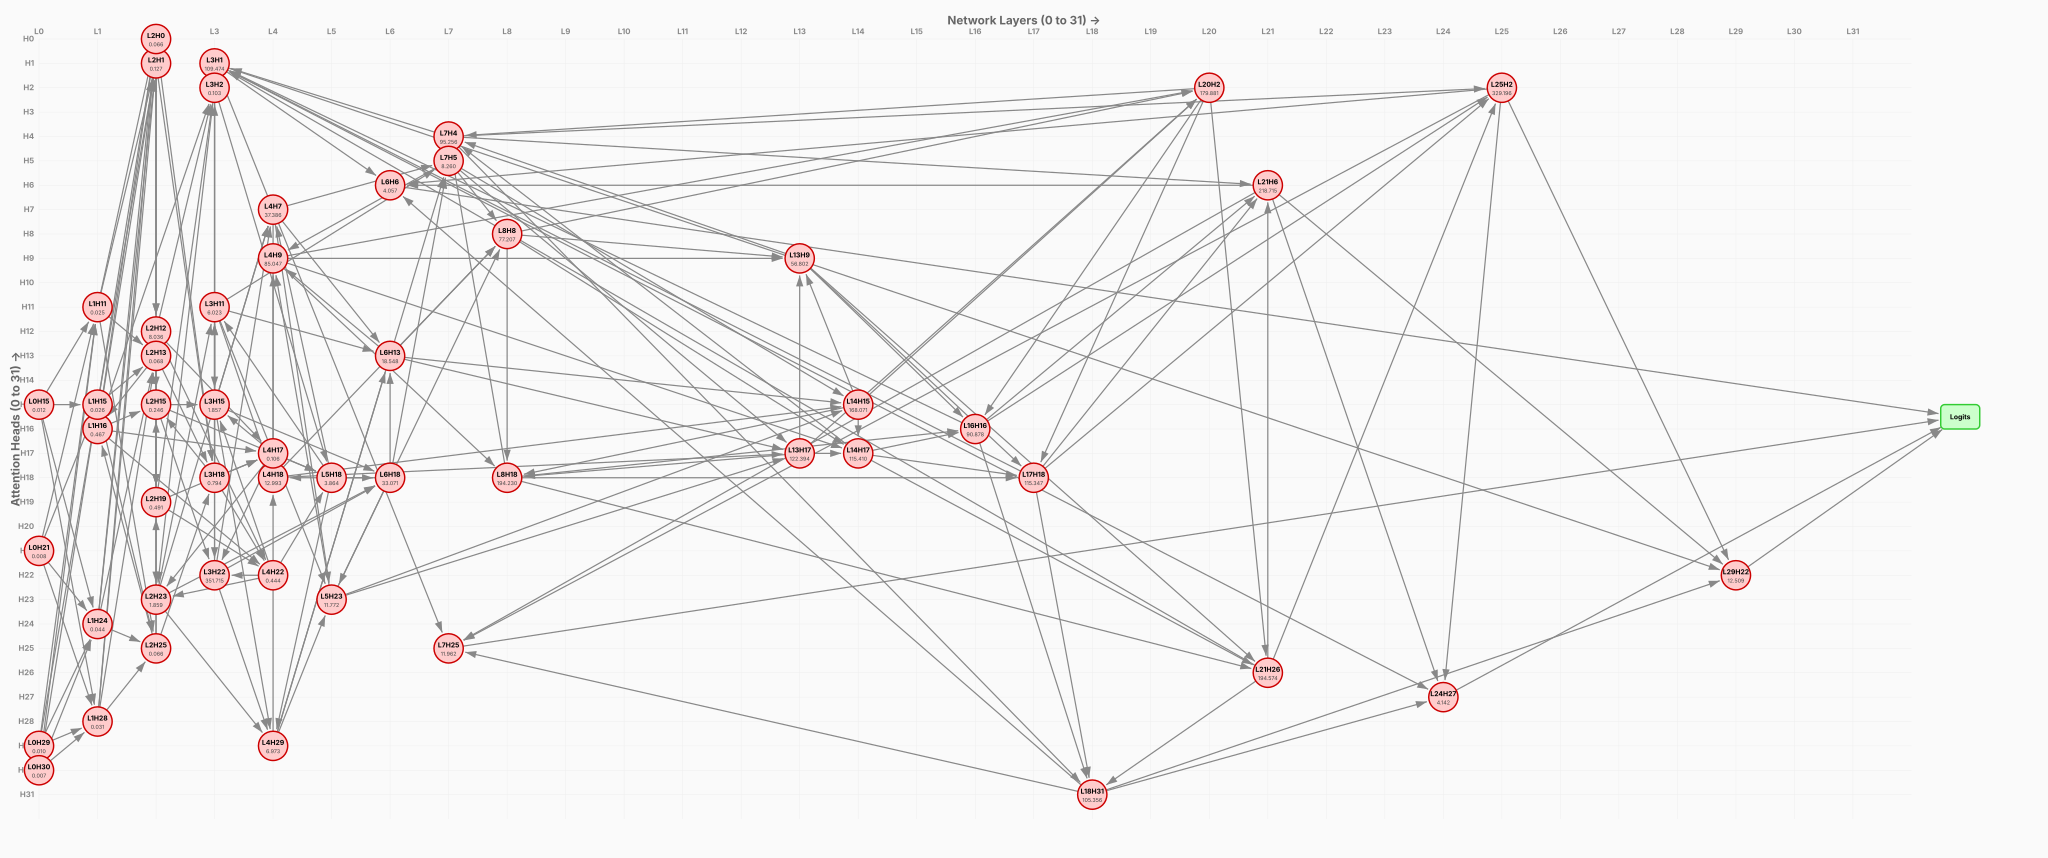


3. Evaluating Faithfulness of Discovered Circuit on 50 examples...
4. Generating & Evaluating Random Control Circuit (52 nodes)...


### Results (`num_outliers=4`, `Total Nodes=52`)

- **Discovered Circuit Faithfulness:** `45.73%`

- **Random Baseline Faithfulness:** `60.57%`

In [11]:
extract_and_evaluate_circuit(num_outliers=4, num_evals=50)


## Evaluating Circuit with `num_outliers=5`

1. Running Iterative Backward Search...
Iteration 0 (target=logits): ['L29H22', 'L7H25', 'L24H27', 'L6H6', 'L31H27']
Iteration 1 (target=['L29H22', 'L7H25', 'L24H27', 'L6H6', 'L31H27']): Selected ['L25H2', 'L21H6', 'L3H1', 'L18H31', 'L21H1']
Iteration 2 (target=['L25H2', 'L21H6', 'L3H1', 'L18H31', 'L21H1']): Selected ['L21H26', 'L17H18', 'L7H4', 'L16H16', 'L19H8']
Iteration 3 (target=['L21H26', 'L17H18', 'L7H4', 'L16H16', 'L19H8']): Selected ['L8H18', 'L20H2', 'L14H17', 'L5H23', 'L13H2']
Iteration 4 (target=['L8H18', 'L20H2', 'L14H17', 'L5H23', 'L13H2']): Selected ['L14H15', 'L13H17', 'L9H29', 'L4H3', 'L16H2']
Iteration 5 (target=['L14H15', 'L13H17', 'L9H29', 'L4H3', 'L16H2']): Selected ['L11H9', 'L13H9', 'L8H22', 'L12H13', 'L10H2']
Iteration 6 (target=['L11H9', 'L13H9', 'L8H22', 'L12H13', 'L10H2']): Selected ['L8H23', 'L7H18', 'L10H20', 'L4H15', 'L9H7']
Iteration 7 (target=['L8H23', 'L7H18', 'L10H20', 'L4H15', 'L9H7']): Selected ['L5H4', 'L4H14', 'L6H9', 'L5H21', 'L5H14']
Iteration 8 

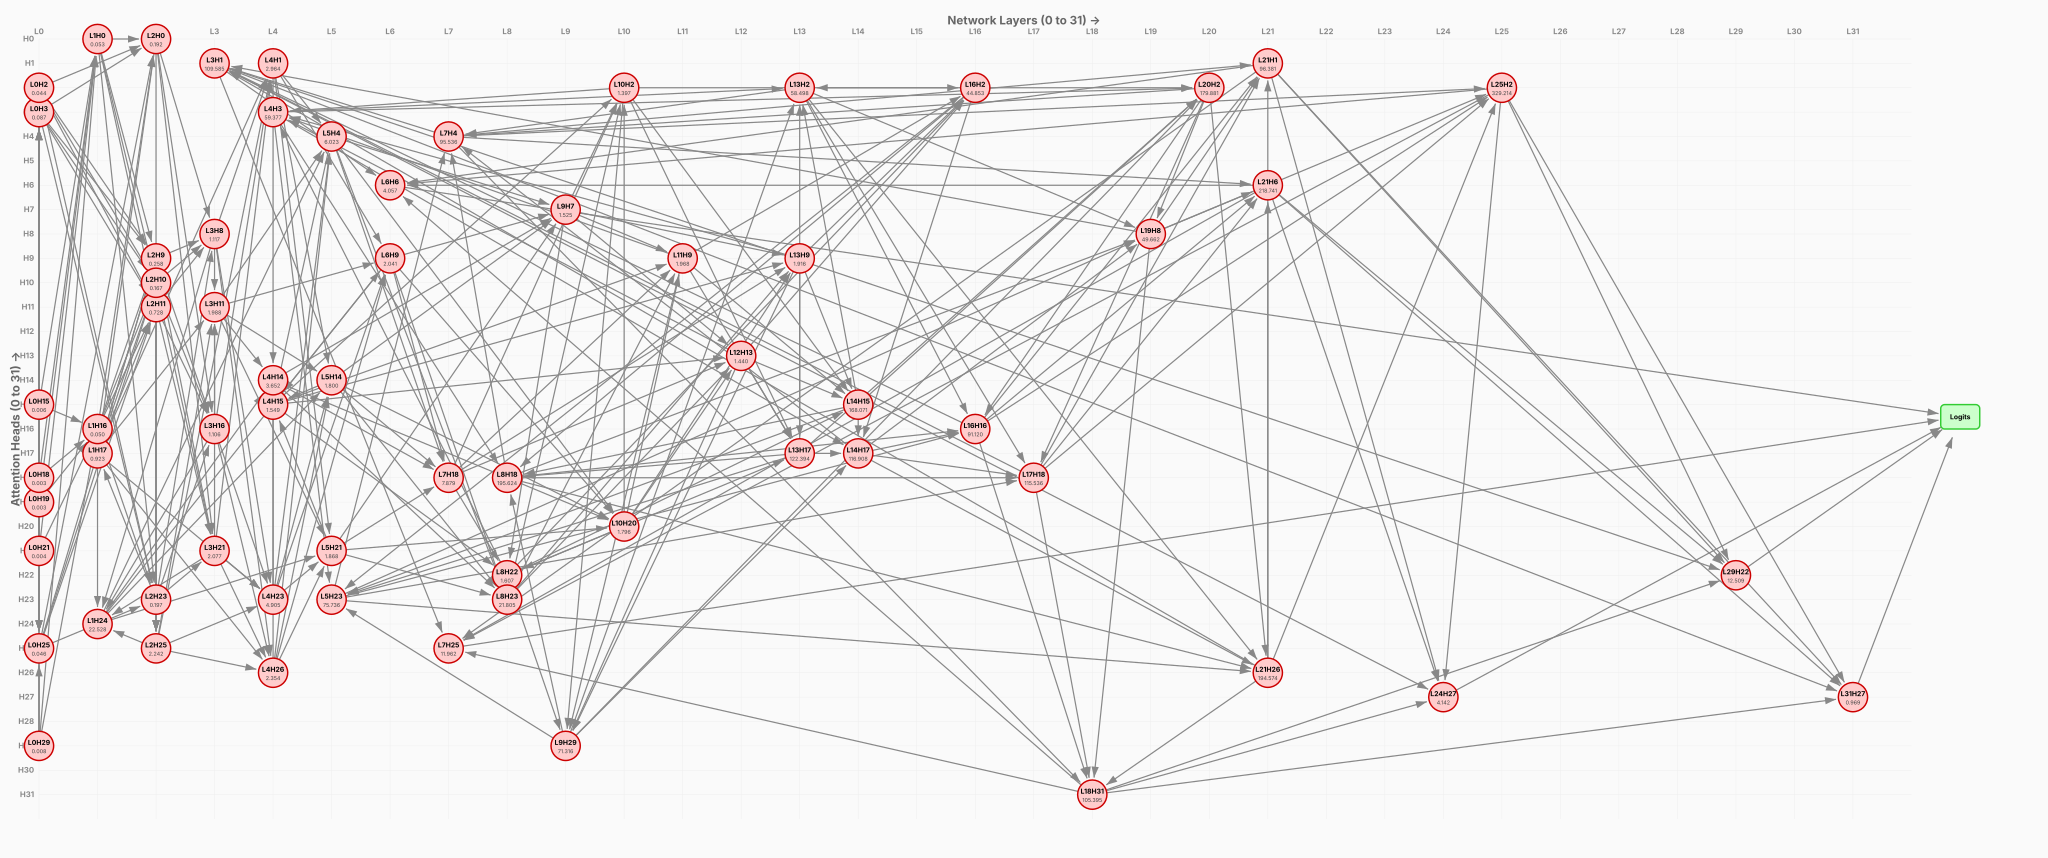


3. Evaluating Faithfulness of Discovered Circuit on 50 examples...
4. Generating & Evaluating Random Control Circuit (65 nodes)...


### Results (`num_outliers=5`, `Total Nodes=65`)

- **Discovered Circuit Faithfulness:** `61.58%`

- **Random Baseline Faithfulness:** `46.00%`

In [12]:
extract_and_evaluate_circuit(num_outliers=5, num_evals=50)
